- Google Drive
- Currency Images
- Load Dataset
- Check Images
- Preprocess
- Train MobileNetV2
- Evaluate

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image

print("TensorFlow version:", tf.__version__)
print("Setup successful! ✅")

TensorFlow version: 2.20.0
Setup successful! ✅


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
BASE_DIR = "/content/drive/MyDrive/Indian_Currency_AI"
DATASET_DIR = os.path.join(BASE_DIR, "Dataset")

print("Project folder:", BASE_DIR)
print("Dataset folder:", DATASET_DIR)

Project folder: /content/drive/MyDrive/Indian_Currency_AI
Dataset folder: /content/drive/MyDrive/Indian_Currency_AI/Dataset


In [ ]:
print("Project exists:", os.path.exists(BASE_DIR))
print("Dataset exists:", os.path.exists(DATASET_DIR))

Project exists: True
Dataset exists: True


In [ ]:
denominations = ["10", "20", "50", "100", "200", "500"]

for denomination in denominations:
    folder = os.path.join(DATASET_DIR, denomination)

    print(
        f"₹{denomination}:",
        "FOUND ✅" if os.path.exists(folder) else "MISSING ❌"
    )

₹10: FOUND ✅
₹20: FOUND ✅
₹50: FOUND ✅
₹100: FOUND ✅
₹200: FOUND ✅
₹500: FOUND ✅


In [ ]:
image_extensions = (".jpg", ".jpeg", ".png", ".webp")

image_counts = {}

for denomination in denominations:
    folder = os.path.join(DATASET_DIR, denomination)

    images = [
        file for file in os.listdir(folder)
        if file.lower().endswith(image_extensions)
    ]

    image_counts[denomination] = len(images)

    print(f"₹{denomination}: {len(images)} images")

₹10: 345 images
₹20: 288 images
₹50: 265 images
₹100: 224 images
₹200: 272 images
₹500: 278 images


In [ ]:
for denomination in denominations:
    folder = os.path.join(DATASET_DIR, denomination)

    valid = 0
    invalid = 0

    for file in os.listdir(folder):
        if file.lower().endswith(image_extensions):
            path = os.path.join(folder, file)

            try:
                with Image.open(path) as img:
                    img.verify()
                valid += 1
            except:
                invalid += 1

    print(
        f"₹{denomination}: "
        f"{valid} valid, {invalid} invalid"
    )

₹10: 345 valid, 0 invalid
₹20: 288 valid, 0 invalid
₹50: 265 valid, 0 invalid
₹100: 224 valid, 0 invalid
₹200: 272 valid, 0 invalid
₹500: 278 valid, 0 invalid


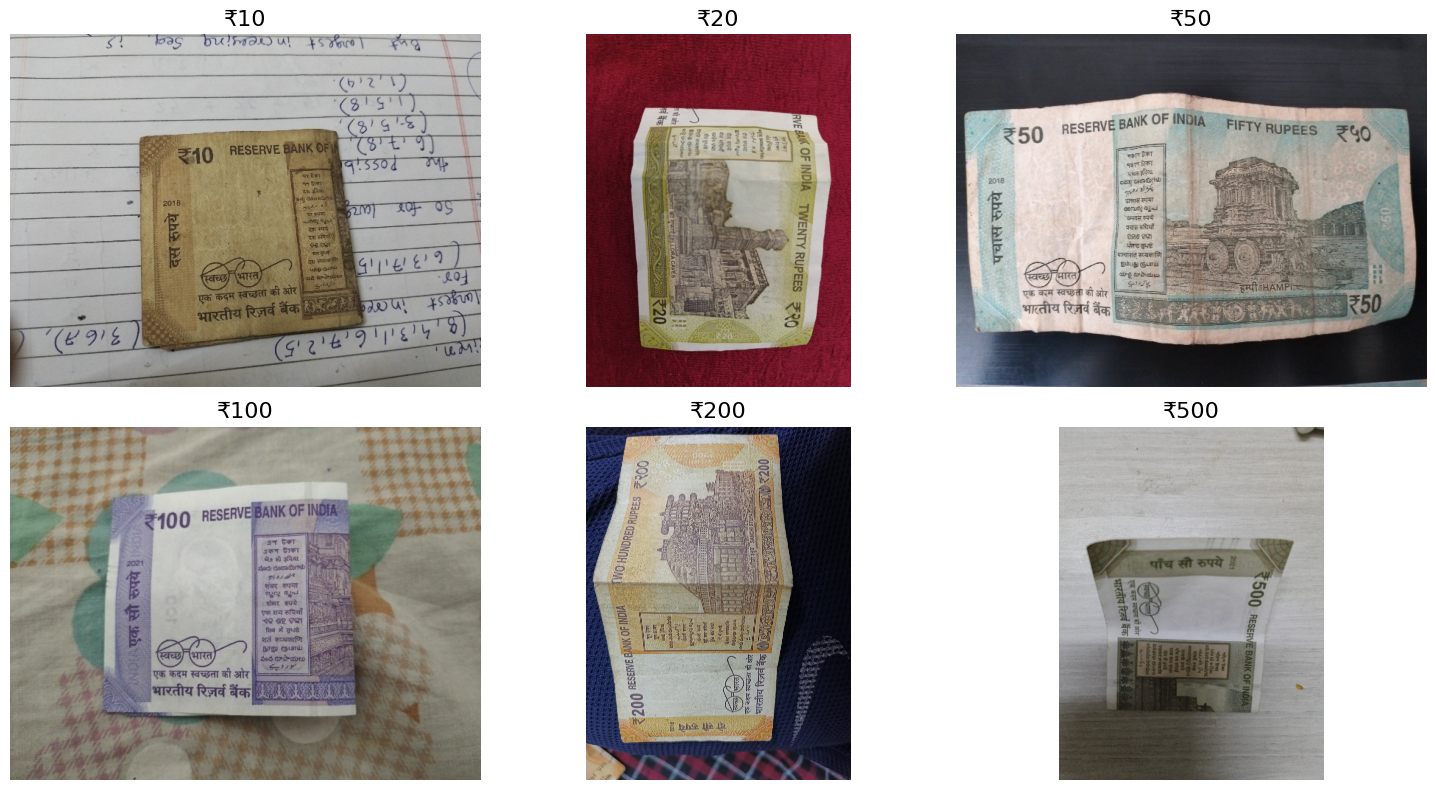

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, denomination in zip(axes.ravel(), denominations):

    folder = os.path.join(DATASET_DIR, denomination)

    images = [
        file for file in os.listdir(folder)
        if file.lower().endswith(image_extensions)
    ]

    if len(images) > 0:
        image_path = os.path.join(folder, images[0])
        image = Image.open(image_path)

        ax.imshow(image)
        ax.set_title(f"₹{denomination}", fontsize=16)
    else:
        ax.set_title(f"₹{denomination} - NO IMAGE")

    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
import os

DATASET_DIR = "/content/drive/MyDrive/Indian_Currency_AI/Dataset"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

print("Dataset loaded successfully! ✅")

Found 1672 files belonging to 6 classes.
Using 1338 files for training.
Found 1672 files belonging to 6 classes.
Using 334 files for validation.
Dataset loaded successfully! ✅


In [ ]:
class_names = train_dataset.class_names

print("Classes:")
for i, name in enumerate(class_names):
    print(i, "→ ₹" + name)

Classes:
0 → ₹10
1 → ₹100
2 → ₹20
3 → ₹200
4 → ₹50
5 → ₹500


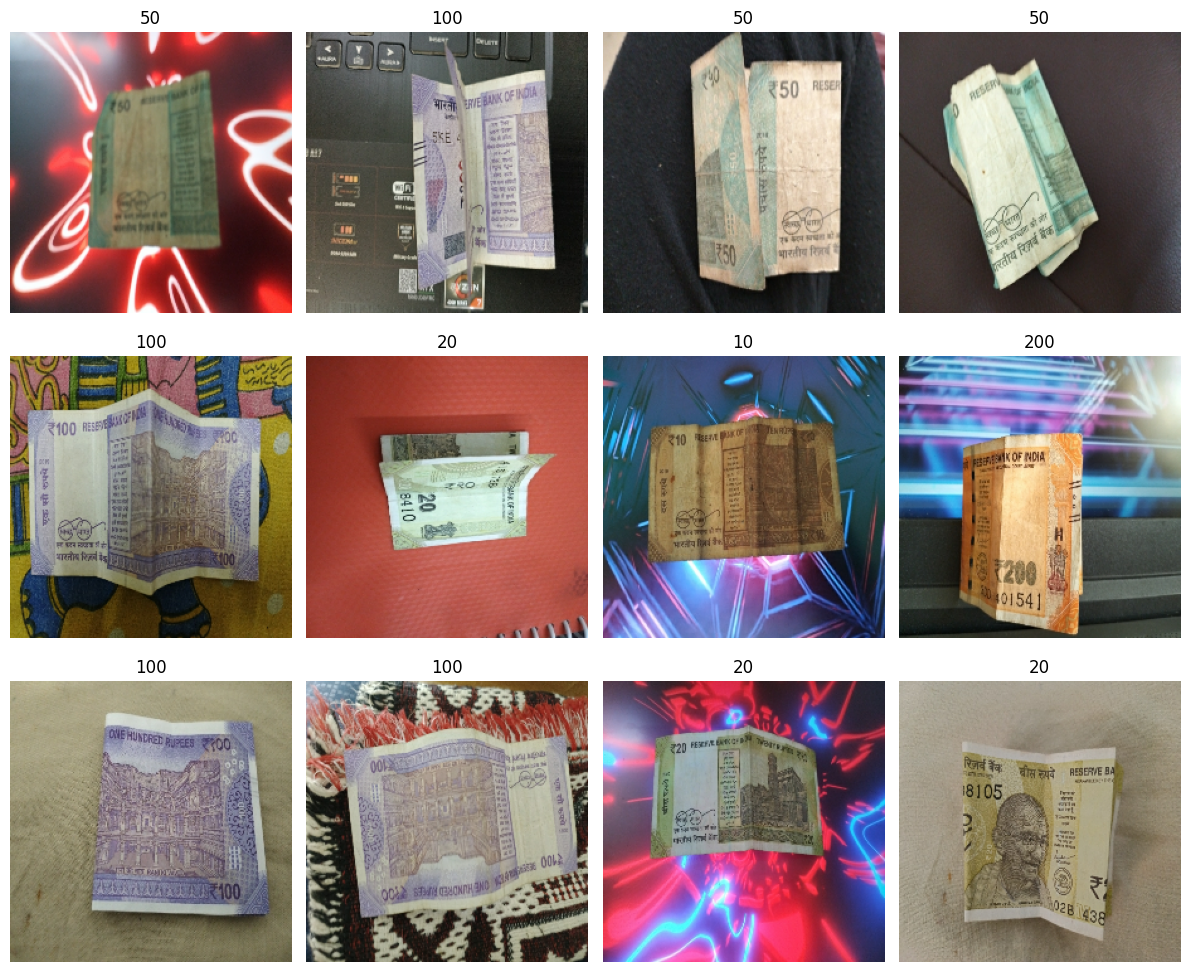

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

for images, labels in train_dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

print("Dataset pipeline optimized! ✅")

Dataset pipeline optimized! ✅


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully! ✅")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 loaded successfully! ✅


In [ ]:
num_classes = len(class_names)

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Scale pixel values from [0,255] to [-1,1]
    layers.Rescaling(1./127.5, offset=-1),

    # Pretrained feature extractor
    base_model,

    # Convert feature maps into a vector
    layers.GlobalAveragePooling2D(),

    # Reduce overfitting
    layers.Dropout(0.2),

    # Our 6 currency classes
    layers.Dense(num_classes, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully! ✅")

Model compiled successfully! ✅


In [ ]:
EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS
)

Epoch 1/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 86s 2s/step - accuracy: 0.2227 - loss: 1.9589 - val_accuracy: 0.3174 - val_loss: 1.6945
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 88s 2s/step - accuracy: 0.2818 - loss: 1.7739 - val_accuracy: 0.3593 - val_loss: 1.5827
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.3371 - loss: 1.6590 - val_accuracy: 0.4222 - val_loss: 1.4938
Epoch 4/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 75s 2s/step - accuracy: 0.3767 - loss: 1.5587 - val_accuracy: 0.4641 - val_loss: 1.4093
Epoch 5/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 87s 2s/step - accuracy: 0.4253 - loss: 1.4669 - val_accuracy: 0.5269 - val_loss: 1.3309
Epoch 6/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.4686 - loss: 1.3836 - val_accuracy: 0.5689 - val_loss: 1.2616
Epoch 7/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 73s 2s/step - accuracy: 0.5157 - loss: 1.3134 - val_accuracy: 0.6287 - val_loss: 1.1979
Epoch 8/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.5419 - loss: 1.2469 - val_accuracy: 0.6467 - val_loss:

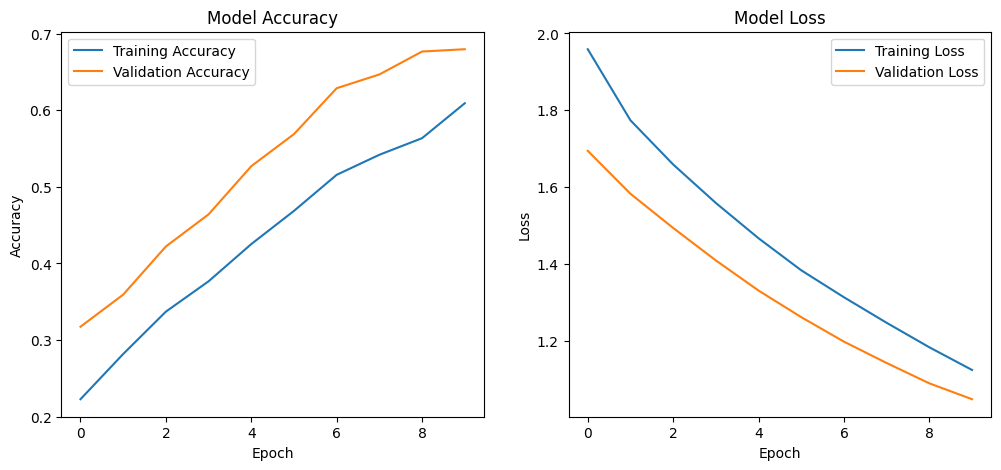

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Get true labels and predictions
y_true = []
y_pred = []

for images, labels in validation_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Prediction completed! ✅")

Prediction completed! ✅


In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

          10     0.6351    0.7581    0.6912        62
         100     0.5714    0.5854    0.5783        41
          20     0.5692    0.6727    0.6167        55
         200     0.7556    0.6800    0.7158        50
          50     0.7317    0.5556    0.6316        54
         500     0.8209    0.7639    0.7914        72

    accuracy                         0.6796       334
   macro avg     0.6807    0.6693    0.6708       334
weighted avg     0.6901    0.6796    0.6807       334



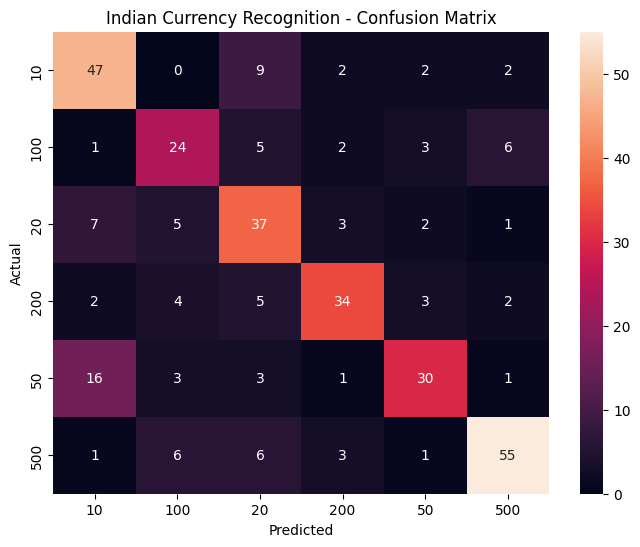

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Indian Currency Recognition - Confusion Matrix")

plt.show()

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10)
])

print("Data augmentation created! ✅")

Data augmentation created! ✅


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

base_model_v2 = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model_v2.trainable = False

model_v2 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Rescaling(
        1./127.5,
        offset=-1
    ),

    base_model_v2,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(
        num_classes,
        activation="softmax"
    )
])

model_v2.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Improved model compiled! ✅")

Improved model compiled! ✅


In [ ]:
EPOCHS = 15

history_v2 = model_v2.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS
)

Epoch 1/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - accuracy: 0.1659 - loss: 2.1698 - val_accuracy: 0.2096 - val_loss: 1.9058
Epoch 2/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.2197 - loss: 1.9970 - val_accuracy: 0.2904 - val_loss: 1.7834
Epoch 3/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.2526 - loss: 1.8601 - val_accuracy: 0.3383 - val_loss: 1.6793
Epoch 4/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.2877 - loss: 1.7754 - val_accuracy: 0.3952 - val_loss: 1.5865
Epoch 5/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 149s 2s/step - accuracy: 0.3408 - loss: 1.6397 - val_accuracy: 0.4521 - val_loss: 1.5008
Epoch 6/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.3871 - loss: 1.5376 - val_accuracy: 0.4880 - val_loss: 1.4223
Epoch 7/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 136s 2s/step - accuracy: 0.3849 - loss: 1.5233 - val_accuracy: 0.5359 - val_loss: 1.3600
Epoch 8/15
42/42 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.4425 - loss: 1.4343 - val_accuracy: 0.5629 - val_los

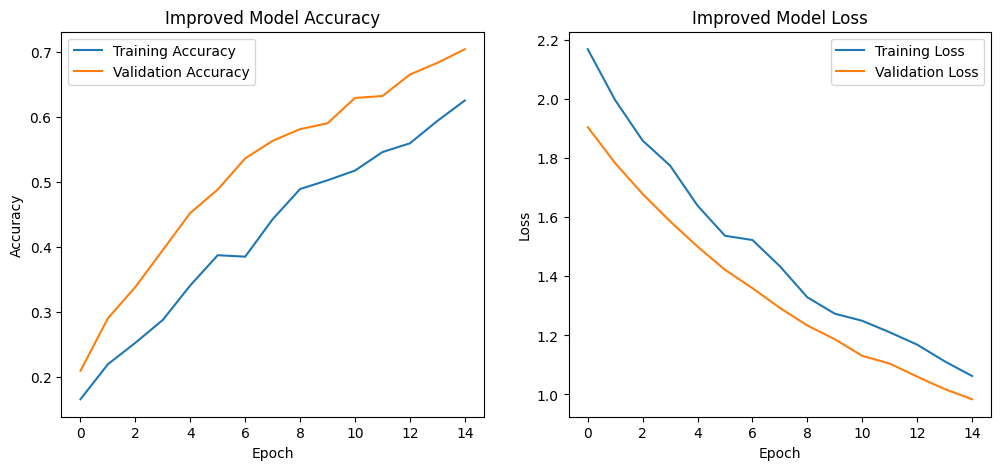

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history_v2.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_v2.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Improved Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history_v2.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v2.history["val_loss"],
    label="Validation Loss"
)

plt.title("Improved Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [ ]:
y_true_v2 = []
y_pred_v2 = []

for images, labels in validation_dataset:
    predictions = model_v2.predict(
        images,
        verbose=0
    )

    y_true_v2.extend(labels.numpy())
    y_pred_v2.extend(
        np.argmax(predictions, axis=1)
    )

y_true_v2 = np.array(y_true_v2)
y_pred_v2 = np.array(y_pred_v2)

print(
    classification_report(
        y_true_v2,
        y_pred_v2,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

          10     0.6154    0.9032    0.7320        62
         100     0.5957    0.6829    0.6364        41
          20     0.6724    0.7091    0.6903        55
         200     0.7838    0.5800    0.6667        50
          50     0.8537    0.6481    0.7368        54
         500     0.8000    0.6667    0.7273        72

    accuracy                         0.7036       334
   macro avg     0.7202    0.6983    0.6982       334
weighted avg     0.7259    0.7036    0.7034       334



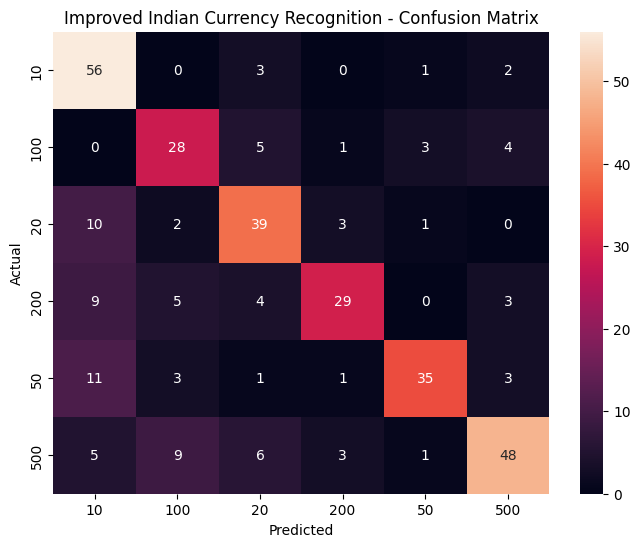

In [ ]:
cm_v2 = confusion_matrix(
    y_true_v2,
    y_pred_v2
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_v2,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(
    "Improved Indian Currency Recognition - Confusion Matrix"
)

plt.show()

In [ ]:
base_model_v2.trainable = True

# Freeze the earlier layers
for layer in base_model_v2.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model_v2.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Total MobileNetV2 layers:", len(base_model_v2.layers))
print(
    "Trainable layers:",
    sum(layer.trainable for layer in base_model_v2.layers)
)

Total MobileNetV2 layers: 154
Trainable layers: 19


In [ ]:
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning! ✅")

Model recompiled for fine-tuning! ✅


In [ ]:
FINE_TUNE_EPOCHS = 10

history_finetune = model_v2.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=FINE_TUNE_EPOCHS
)

Epoch 1/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 104s 2s/step - accuracy: 0.6241 - loss: 1.0058 - val_accuracy: 0.7186 - val_loss: 0.7935
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.7257 - loss: 0.7754 - val_accuracy: 0.8084 - val_loss: 0.6359
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.7571 - loss: 0.6747 - val_accuracy: 0.8263 - val_loss: 0.5810
Epoch 4/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.7907 - loss: 0.5825 - val_accuracy: 0.8473 - val_loss: 0.5017
Epoch 5/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.8161 - loss: 0.5089 - val_accuracy: 0.8713 - val_loss: 0.4559
Epoch 6/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.8378 - loss: 0.4754 - val_accuracy: 0.8593 - val_loss: 0.4167
Epoch 7/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step - accuracy: 0.8513 - loss: 0.3951 - val_accuracy: 0.8743 - val_loss: 0.4049
Epoch 8/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step - accuracy: 0.8602 - loss: 0.3843 - val_accuracy: 0.8802 - v

In [ ]:
y_true_ft = []
y_pred_ft = []

for images, labels in validation_dataset:
    predictions = model_v2.predict(
        images,
        verbose=0
    )

    y_true_ft.extend(labels.numpy())
    y_pred_ft.extend(
        np.argmax(predictions, axis=1)
    )

y_true_ft = np.array(y_true_ft)
y_pred_ft = np.array(y_pred_ft)

In [ ]:
print(
    classification_report(
        y_true_ft,
        y_pred_ft,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

          10     0.8769    0.9194    0.8976        62
         100     0.8684    0.8049    0.8354        41
          20     0.8596    0.8909    0.8750        55
         200     0.9348    0.8600    0.8958        50
          50     0.9400    0.8704    0.9038        54
         500     0.8718    0.9444    0.9067        72

    accuracy                         0.8892       334
   macro avg     0.8919    0.8817    0.8857       334
weighted avg     0.8908    0.8892    0.8890       334



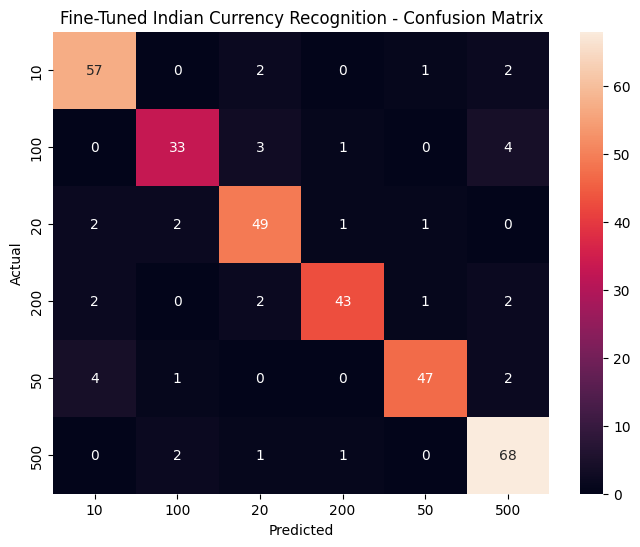

In [ ]:
cm_ft = confusion_matrix(
    y_true_ft,
    y_pred_ft
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_ft,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(
    "Fine-Tuned Indian Currency Recognition - Confusion Matrix"
)

plt.show()